In [1]:
#import Libraries
!pip3 install pandas
%pip install matplotlib
%pip install seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
#import database

In [3]:
try:
    conn = sqlite3.connect("/Users/himanshurawat/Downloads/customer_churn (1).db")

    sql_query = """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """

    tables = pd.read_sql(sql_query, conn)
    #create dataframe
    for table_name in tables["name"]:
        df = pd.read_sql(f"SELECT * FROM {table_name}",conn)
        globals()[f"df_{table_name}"]=df
        print(f"Created dataframe : df_{table_name}")

except Exception as e:
    print(e)

finally:
    conn.close()   

Created dataframe : df_db_customer
Created dataframe : df_db_subscription
Created dataframe : df_db_support


In [4]:
#print table name and column name

In [5]:
conn = sqlite3.connect('/Users/himanshurawat/Downloads/customer_churn (1).db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")

    # Get column information
    column_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(column_query, conn)

    print("Columns:")
    print(columns['name'].tolist())

# Close connection 
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [6]:
# data cleaning

In [7]:
#df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [8]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [9]:
# a. rename column - name
# b. drop columns -interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values - country

In [10]:
# a. rename column - name

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True)
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [11]:
# b. drop columns -interest and pincode

# df_db_customer.drop(df_db_customer.columns[-2:],axis =1)
# df_db_customer.drop(df_db_customer.columns[6:],axis =1)
df_db_customer.drop(columns = ['interests','pincode'] , inplace = True)

In [12]:
#df_db_customer.info()

In [13]:
# c. change datatype -dob

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [14]:
# d. data standardization - gender

df_db_customer['gender']  = df_db_customer['gender'].replace({'Men' : 'Male', 'Women':'Female','Femalle':'Female'})
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [15]:
# e. fix missing values - country
df_db_customer[df_db_customer['country'].isna()]  #jha jha pe null(true) value thi wo return hoga

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [16]:
#df_db_customer['country'].fillna('Nahi pata')  #jha pe null tha wha pe nahi pta fill hojayega
# df_db_customer[['country','state']]

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [17]:
# df_db_customer[df_db_customer['country'].isna()]
# df_db_customer[['country','state']]

In [18]:
# 2nd table

df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [19]:
date_col = ['subscription_start_date','renewal_date','cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [20]:
# 3rd table

df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [21]:
#df_db_support.drop(columns= ['col_1','comment'],inplace = True)


In [22]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [23]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [24]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
 4   col_1           0 non-null      object        
 5   comment         4 non-null      str           
dtypes: datetime64[us](1), int64(1), object(1), str(3)
memory usage: 564.0+ bytes


In [25]:
#3 Feature engineering and data analysis

In [26]:
#create a new column using a existing column - churn flag
df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [27]:
df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0


In [28]:
# merging the other tables with subscription table
# first fix support table duplicates then merge

df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid', how = 'left')
    .merge(df_db_support, on = 'customerid', how = 'left'))

In [29]:
df_db_subscription.shape    #yha pe 21 rows h lkin join k badd 23 hogye mtlb khi pe record mai gadbad h

(21, 12)

In [30]:
df.shape

(23, 22)

In [31]:
df_db_subscription['customerid'].nunique()

21

In [32]:
df_db_customer['customerid'].nunique()

21

In [33]:
df_db_support['customerid'].nunique()

7

In [34]:
df_db_support['customerid'].size     #here is the problem 2 row yha se extra aari h

9

In [35]:
#df_db_support

In [36]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')
df_db_support

,customerid,complaint_date,escalations,csat_score,col_1,comment,complaint_count
0,0003-MKNFE,2024-08-28,N,60,None,service issue,2
1,0003-MKNFE,2024-08-28,Y,10,None,demaned refund,2
2,0013-EXCHZ,2024-01-20,Y,20,None,NaN,1
3,0013-MHZWF,2025-03-18,N,90,None,guidance to renew,1
4,0013-SMEOE,2024-11-01,N,30,None,NaN,1
5,0017-IUDMW,2024-04-10,Y,25,None,NaN,1
6,0019-EFAEP,2024-09-27,Y,30,None,NaN,1
7,0022-TCJCI,2024-09-13,Y,10,None,NaN,2
8,0022-TCJCI,2024-09-14,N,90,None,received refund,2


In [37]:
 df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep = 'last')

In [38]:
df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid', how = 'left')
    .merge(df_db_support, on = 'customerid', how = 'left'))

In [39]:
df.shape

(21, 23)

In [40]:
df.to_csv('exported_churn_data.csv',index = False)

In [41]:
# Data Analysis

In [42]:
# 1. Churn rate

In [43]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment',
       'complaint_count'],
      dtype='str')

In [44]:
churn_rate = df['churn_flag'].mean()*100
print('Churn rate = ',round(churn_rate,2),'%')

Churn rate =  28.57 %


In [45]:
# 2. Retention rate
retention_rate = 100 - churn_rate
print('Retention rate = ',round(retention_rate,2),'%')

Retention rate =  71.43 %


In [46]:
# 3. Churn by plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name = 'churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [47]:
# 4 a. Churn by state + sum(revenue) & count of users
# 4 b. Churn by subscription type + sum(revenue) & count of users

In [48]:
# 5. ARPU - average revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ',round(arpu,2))

ARPU =  18.85


In [49]:
# 6. Avg customer Tenure
# count of days users has used our service : cancellation date else currnt date

today = pd.Timestamp.today()
df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date']-df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)


avg_tenure = df['tenure_days'].mean()
print('Average tenure',round(avg_tenure,0))

Average tenure 1575.0


In [50]:
# 7. Revenue at risk -revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1,'monthly_charges'].sum()
print('Revenue at risk (Rs k)',revenue_at_risk)

Revenue at risk (Rs k) 73.94


In [51]:
# 8. Escalation Rate 
escalation_rate = (df['escalations']=='Y').mean()*100
print('Escalation rate = ',round(escalation_rate,2),'%')

Escalation rate =  19.05 %


In [52]:
# 9. Avg Complaint rate per user
avg_complaints = df['complaint_count'].sum()/df['customerid'].nunique()
print('Avg complaints per user : ',round(avg_complaints,2))

Avg complaints per user :  0.43


In [53]:
# 10. Correlation Escalation Vs Churn
df['escalations'] = np.where(df['escalations']=='Y',1,0)  #encoding string to int type
corr_df = df[['escalations','churn_flag']].dropna()

correlation =  corr_df['escalations'].corr(df['churn_flag'])
print('Correlation between escalation Vs churn is = ',round(correlation,2))

Correlation between escalation Vs churn is =  0.77


In [54]:
# 11. Churn risk - create a column using existing column
conditions = [
    (df['churn_score']<50),
    (df['churn_score']>=50) & (df['churn_score']<70),
    (df['churn_score']>=70)
]

choices = ['low','med','high']
df['churn_risk'] = np.select(conditions,choices,default = 'unknown')

In [55]:
df[['churn_risk','churn_score']].head()

,churn_risk,churn_score
0,low,12
1,high,91
2,low,34
3,low,8
4,high,88


In [56]:
# 4. data visualization using matplotlib

In [57]:
df_visual = df.copy()

In [58]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment',
       'complaint_count', 'tenure_days', 'churn_risk'],
      dtype='str')

In [59]:
# 4.1 Monthly churn trend (this is time series KPI)

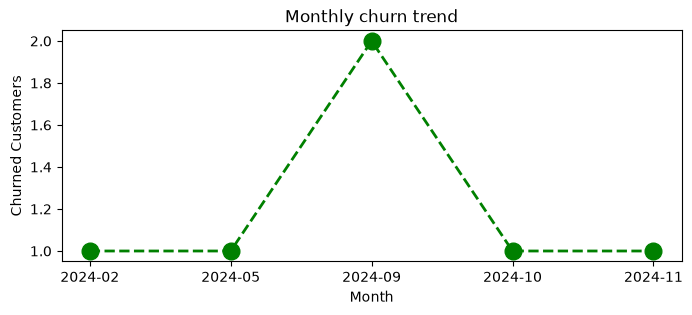

In [60]:
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')
churn_trend = df_visual[df['churn_flag']==1].groupby('cancellation_month').size()

plt.figure(figsize = (8,3))
plt.plot(churn_trend.index.astype('str'),churn_trend.values, color = 'green', marker = 'o', linestyle = 'dashed', linewidth = 2, markersize = 12)

plt.title('Monthly churn trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

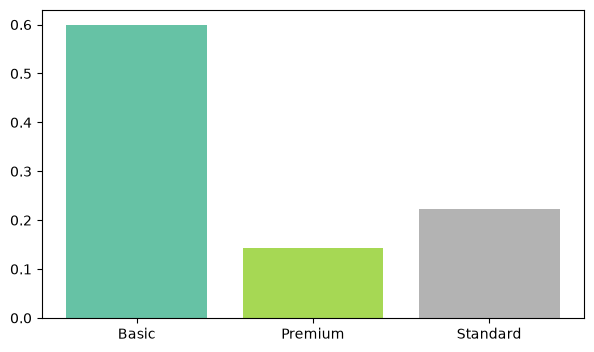

In [61]:
# 4.2 Churn by plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

#colors = ['yellow','purple','blue']
colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(7,4))
plt.bar(churn_plan.index,churn_plan.values,color = colors)
plt.show()

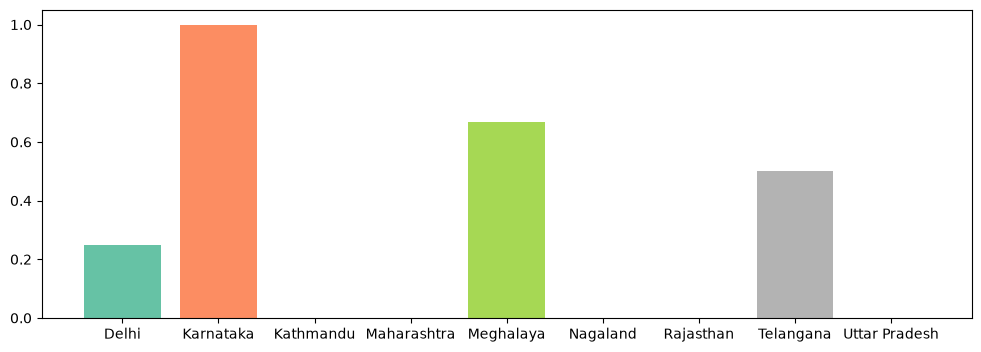

In [62]:
# Churn by states
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

#colors = ['yellow','purple','blue']
colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(12,4))
plt.bar(churn_plan.index,churn_plan.values,color = colors)
plt.show()

In [63]:
# Visualization using Seaborn

In [64]:
# Encoding - convert string to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment',
       'complaint_count', 'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [65]:
df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [66]:
df_encoded.head()

NameError: name 'df_encoded' is not defined

In [ ]:
# incorrect method of encoding as number are not assigned based on priority
df_encoded = df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()
categorial_cols = ['plan_type','contract_type','churn_risk']

for col in categorial_cols:
    df_encoded[col]= df_encoded[col].astype('category').cat.codes

<Axes: >

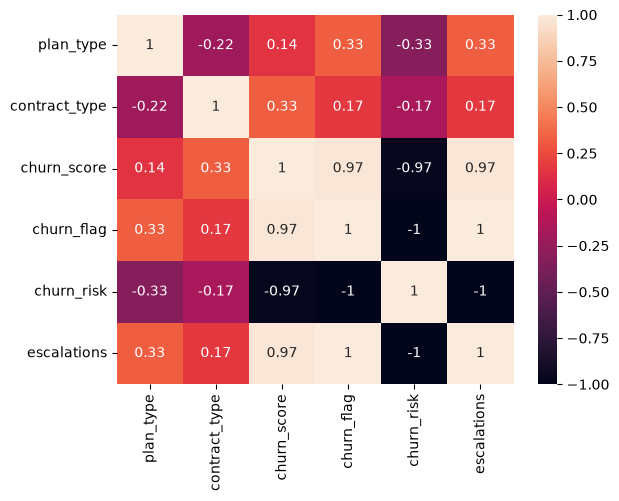

In [ ]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(),annot = True)

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# correct method of encoding - based on priority
df_encoded = df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']]

order_mappings = {
    'plan_type':['Basic','Standard','Premium'],
    'contract_type':['Monthly','Annual'],
    'churn_risk':['low','medium','high']
    }

for col,order in order_mappings.items():
    df_encoded[col]= pd.Categorical(df_encoded[col].astype('category'),categories = order,ordered = True).codes

In [ ]:
df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [ ]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

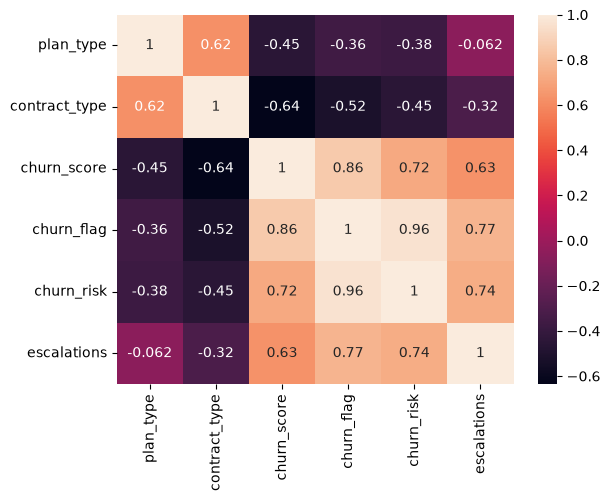

In [ ]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(),annot = True)

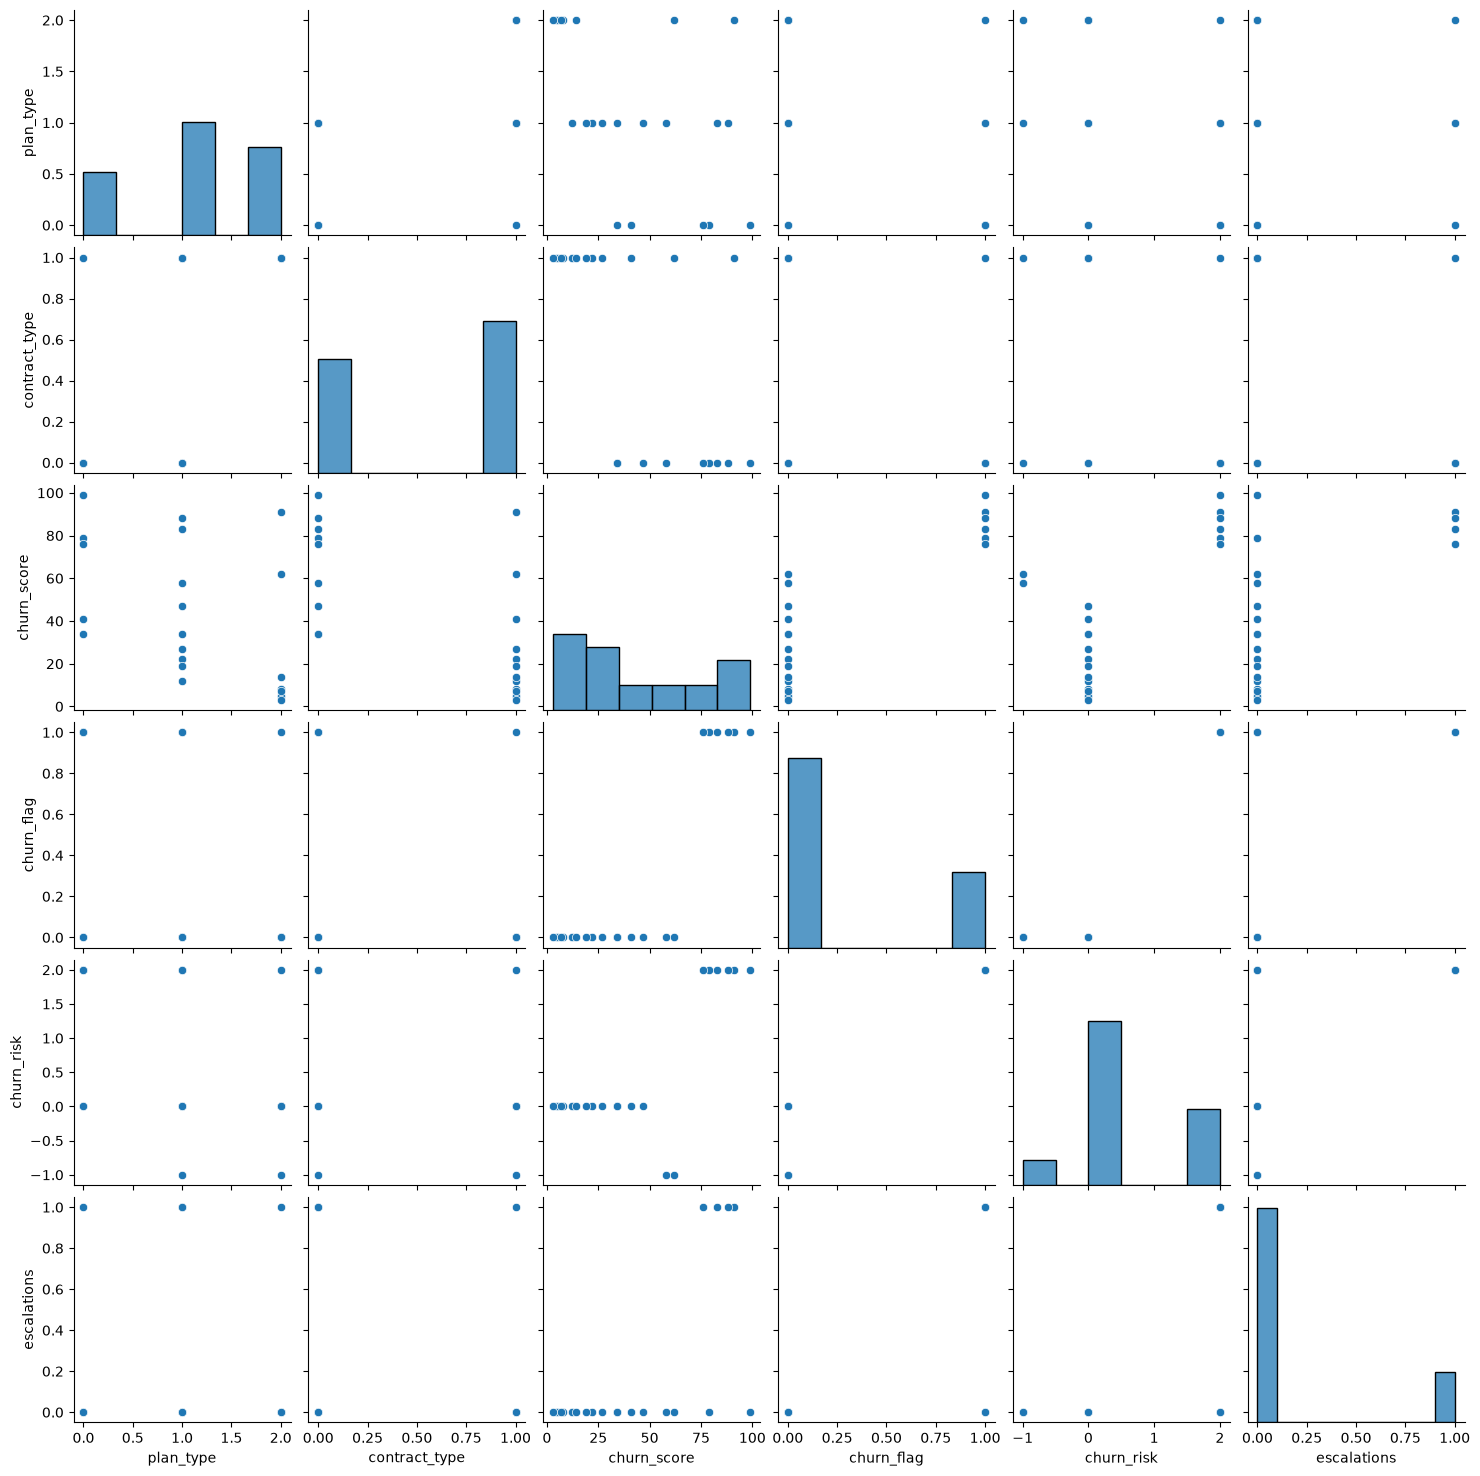

In [ ]:
# pairplot - relationship in a dataset
sns.pairplot(df_encoded)

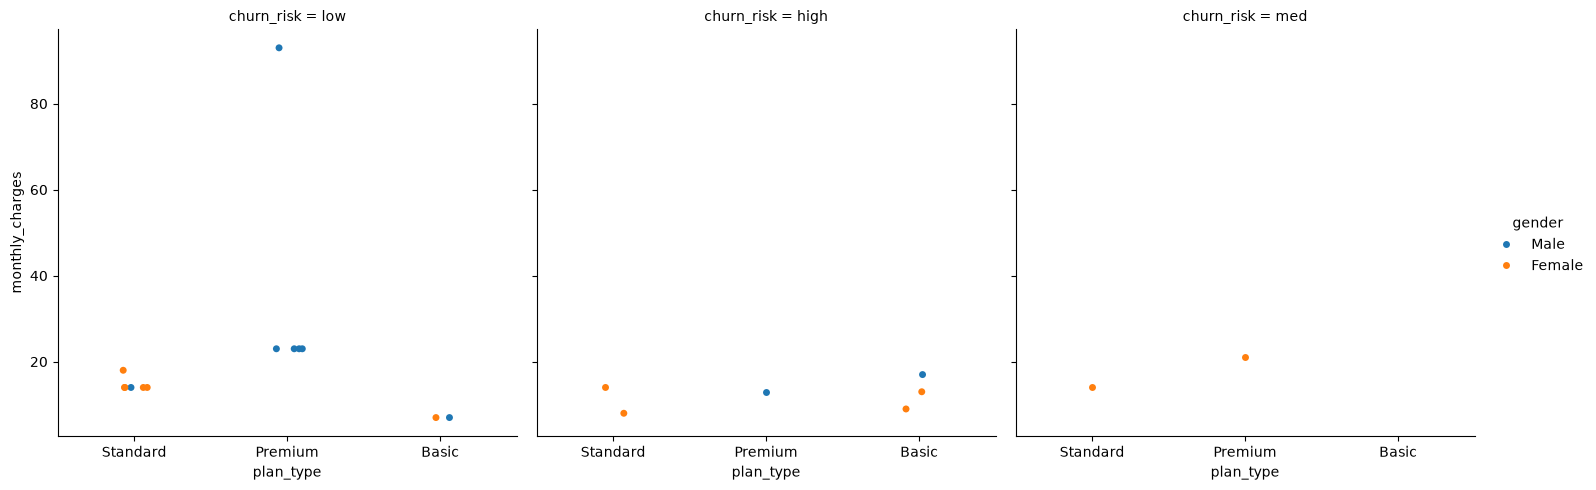

In [ ]:
# catplt/Facegrid plot - multi-dim comparison
sns.catplot(data = df_visual,
         x = 'plan_type',
         y = 'monthly_charges',
         hue = 'gender',
         col = 'churn_risk')   

In [ ]:
# pivot Table

In [ ]:
pd.pivot_table(
    df_visual,
    index = 'plan_type',
    values = 'churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [ ]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment',
       'complaint_count', 'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [ ]:
pd.pivot_table(
    df_visual,
    index = 'plan_type',
    values = ['monthly_charges','customerid','churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [ ]:
# working with SQL in python(pandas)

In [ ]:
# create db in sql
conn = sqlite3.connect('test_database.sqlite')

#table details
# conn.execute('CREATE TABLE users(first_name TEXT, country TEXT,budget INTEGER)')

#commit and save
conn.commit()

In [ ]:
# insert data

cursor = conn.cursor()

# write sql query to insert record in sql table
cursor.execute(
    """
        INSERT INTO users VALUES
        ('Madhav','India',5000),
        ('Ritik','Germany','2500'),
        ('Vishakha','India',3500)
    """
)

# commit and save
conn.commit()

print('Data inserted successfully')

Data inserted successfully


In [ ]:
# check inserted data in table
conn = sqlite3.connect('test_database.sqlite')
query = """SELECT * FROM users"""

df_results = pd.read_sql(query,conn)
df_results.head()

,first_name,country,budget
0,Madhav,india,5000
1,Ritik,Germany,2500
2,Vishakha,India,3500
3,Madhav,india,5000
4,Ritik,Germany,2500


In [ ]:
# aggregation 
query = """
        SELECT country, sum(budget) as total_budget
        FROM users
        GROUP BY country
"""
df_agg = pd.read_sql(query,conn)
df_agg

,country,total_budget
0,Germany,7500
1,India,15500
2,india,10000


In [ ]:
# always close the connection with database once the task is over
conn.close()